# Financial News Sentiment with FinBERT

An exploratory analysis of NVIDIA news sentiment and its relationship with stock returns from January to February 2026.


Financial news contains qualitative information that is difficult to compare directly with market data. This project uses pretrained FinBERT to extract sentiment from NVIDIA-related headlines and examines its relationship with daily stock returns.

The analysis covers January to February 2026 and focuses on associations rather than stock-price prediction.


In [3]:
from pathlib import Path

import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from transformers import AutoTokenizer, AutoModelForSequenceClassification

## 1. Data Preparation

In [4]:
from zipfile import ZipFile

data_dir = Path("finbert_canonical_v1")

if not data_dir.exists():
    with ZipFile("finbert_canonical_v1.zip") as archive:
        archive.extractall(".")
#Build news dataset

# Load frozen news data
data_dir = Path("finbert_canonical_v1")

news = pd.read_json(
    data_dir / "nvda_news_combined_raw_2026.json"
)

# Standardize fields
news["Date"] = pd.to_datetime(news["Date"]).dt.date

news["title_clean"] = (
    news["title"].str.strip().str.lower()
    .str.replace(r"\s+", " ", regex=True)
)

news["url_clean"] = news["url"].str.strip()

news["publisher_name"] = news["publisher"].apply(
    lambda p: p.get("title", "Unknown")
    if isinstance(p, dict) else str(p)
)

news["publisher_clean"] = (
    news["publisher_name"].str.strip().str.lower()
)

# Remove duplicate and invalid records
news_clean = news.drop_duplicates(subset="url_clean")

news_clean = news_clean.drop_duplicates(
    subset=["Date", "publisher_clean", "title_clean"]
)

news_clean = news_clean[
    news_clean["Date"].notna() &
    news_clean["title_clean"].ne("")
]

news_clean = news_clean.sort_values(
    ["Date", "title_clean"]
).reset_index(drop=True)

print("Raw articles:", len(news))
print("Cleaned articles:", len(news_clean))
print("Publishers:", news_clean["publisher_name"].nunique())
print("Publication dates:", news_clean["Date"].nunique())

assert len(news_clean) == 1526



Raw articles: 1528
Cleaned articles: 1526
Publishers: 364
Publication dates: 58


In [5]:
required_files = [
    "nvda_news_combined_raw_2026.json",
    "nvda_stock_returns_2026_jan_feb.csv",
    "nvda_news_finbert_scored_2026.json",
    "manifest.json"
]

for filename in required_files:
    print(filename, (data_dir / filename).is_file())

nvda_news_combined_raw_2026.json True
nvda_stock_returns_2026_jan_feb.csv True
nvda_news_finbert_scored_2026.json True
manifest.json True


## 2. FinBERT Sentiment Classification

In [6]:
model_name = "ProsusAI/finbert"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device)
model.eval()

labels = {
    label.lower(): int(idx)
    for idx, label in model.config.id2label.items()
}

assert {"positive", "negative", "neutral"} == set(labels)

titles = news_clean["title"].tolist()
batches = []

with torch.inference_mode():
    for i in range(0, len(titles), 32):
        inputs = tokenizer(
            titles[i:i + 32],
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt"
        ).to(device)

        logits = model(**inputs).logits
        batches.append(torch.softmax(logits, dim=1).cpu())

probs = torch.cat(batches).numpy()

news_scored = news_clean.copy()

for label in labels:
    news_scored[f"prob_{label}"] = probs[:, labels[label]]

news_scored["sentiment_score"] = (
    news_scored["prob_positive"] - news_scored["prob_negative"]
)

news_scored["sentiment_label"] = [
    model.config.id2label[i].lower()
    for i in probs.argmax(axis=1)
]

print("Headlines scored:", len(news_scored))
print(news_scored["sentiment_label"].value_counts())
print("\nMean sentiment:", round(news_scored["sentiment_score"].mean(), 4))


config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Headlines scored: 1526
sentiment_label
neutral     1045
positive     284
negative     197
Name: count, dtype: int64

Mean sentiment: 0.0912


In [7]:
# Keep headlines explicitly mentioning NVIDIA or NVDA

news_scored["title_mentions_nvda"] = news_scored["title"].str.contains(
    r"\b(?:nvidia|nvda)\b",
    case=False,
    na=False
)

news_primary = news_scored[
    news_scored["title_mentions_nvda"]
].copy()

print("Total headlines:", len(news_scored))
print("NVIDIA-related headlines:", len(news_primary))
print("Excluded headlines:", len(news_scored) - len(news_primary))


Total headlines: 1526
NVIDIA-related headlines: 1498
Excluded headlines: 28


## 3. Daily Sentiment Aggregation

In [8]:
# Daily sentiment by publication date

daily_primary = (
    news_primary.groupby("Date", as_index=False)
    .agg(
        headline_count=("sentiment_score", "size"),
        mean_sentiment=("sentiment_score", "mean")
    )
    .sort_values("Date")
    .reset_index(drop=True)
)

daily_full = (
    news_scored.groupby("Date", as_index=False)
    .agg(
        headline_count=("sentiment_score", "size"),
        mean_sentiment=("sentiment_score", "mean")
    )
    .sort_values("Date")
    .reset_index(drop=True)
)

print("Primary headlines:", daily_primary["headline_count"].sum())
print("Publication dates:", len(daily_primary))
print("\nDaily sentiment statistics:")
print(daily_primary["mean_sentiment"].describe().round(4))

display(daily_primary.head())


Primary headlines: 1498
Publication dates: 58

Daily sentiment statistics:
count    58.0000
mean      0.0634
std       0.1677
min      -0.6111
25%      -0.0336
50%       0.1132
75%       0.1791
max       0.3514
Name: mean_sentiment, dtype: float64


,Date,headline_count,mean_sentiment
0,2026-01-01,18,0.133320
1,2026-01-02,17,0.045758
2,2026-01-03,10,0.066359
3,2026-01-04,3,-0.233893
4,2026-01-05,47,0.193739


## 4. Stock Returns

In [9]:
# NVIDIA stock prices and daily returns

stock = pd.read_csv(
    data_dir / "nvda_stock_returns_2026_jan_feb.csv",
    parse_dates=["Date"]
)

stock["Date"] = stock["Date"].dt.date
stock = stock.sort_values("Date").reset_index(drop=True)

assert len(stock) == 39
assert stock[["Close", "daily_return"]].notna().all().all()

print("Trading days:", len(stock))
print("\nDaily return statistics:")
print(stock["daily_return"].describe().round(4))

display(stock.head())


Trading days: 39

Daily return statistics:
count    39.0000
mean     -0.0010
std       0.0236
min      -0.0546
25%      -0.0138
50%       0.0004
75%       0.0114
max       0.0787
Name: daily_return, dtype: float64


,Date,Close,daily_return
0,2026-01-02,188.409134,0.012601
1,2026-01-05,187.680832,-0.003866
2,2026-01-06,186.802887,-0.004678
3,2026-01-07,188.668518,0.009987
4,2026-01-08,184.608017,-0.021522


## 5. Sentiment and Market Returns

In [10]:
# Match daily sentiment with NVIDIA stock returns

market_sentiment = stock.merge(
    daily_primary[["Date", "headline_count", "mean_sentiment"]],
    on="Date",
    how="left",
    validate="one_to_one"
)

market_sentiment = market_sentiment.sort_values("Date").reset_index(drop=True)

# Return on the following trading session
market_sentiment["next_session_return"] = (
    market_sentiment["daily_return"].shift(-1)
)

print("Trading sessions:", len(market_sentiment))
print("Sessions with news:", market_sentiment["mean_sentiment"].notna().sum())

print("\nValid observations:")
print("Same-date:", market_sentiment[["mean_sentiment", "daily_return"]].dropna().shape[0])
print("Next-session:", market_sentiment[["mean_sentiment", "next_session_return"]].dropna().shape[0])

print("\nTrading dates without news:")
display(market_sentiment.loc[
    market_sentiment["mean_sentiment"].isna(),
    ["Date", "daily_return"]
])

display(market_sentiment.head())


Trading sessions: 39
Sessions with news: 38

Valid observations:
Same-date: 38
Next-session: 37

Trading dates without news:


,Date,daily_return
27,2026-02-11,0.008009


,Date,Close,daily_return,headline_count,mean_sentiment,next_session_return
0,2026-01-02,188.409134,0.012601,17.0,0.045758,-0.003866
1,2026-01-05,187.680832,-0.003866,47.0,0.193739,-0.004678
2,2026-01-06,186.802887,-0.004678,67.0,0.180845,0.009987
3,2026-01-07,188.668518,0.009987,53.0,0.122921,-0.021522
4,2026-01-08,184.608017,-0.021522,50.0,0.130269,-0.000973


## 6. Correlation Analysis


Pearson correlations are calculated for same-date sentiment and returns, as well as returns in the following trading session. Missing sentiment observations are excluded rather than assigned a neutral score.


In [11]:
# Sentiment and stock-return correlations

results = []

for name, return_col in [
    ("Same-date", "daily_return"),
    ("Next-session", "next_session_return")
]:
    paired = market_sentiment[
        ["mean_sentiment", return_col]
    ].dropna()

    test = pearsonr(
        paired["mean_sentiment"],
        paired[return_col]
    )

    ci = test.confidence_interval(confidence_level=0.95)

    results.append({
        "Comparison": name,
        "Observations": len(paired),
        "Pearson r": test.statistic,
        "P-value": test.pvalue,
        "CI lower": ci.low,
        "CI upper": ci.high
    })

correlations = pd.DataFrame(results)

display(correlations.round(4))


,Comparison,Observations,Pearson r,P-value,CI lower,CI upper
0,Same-date,38,0.2283,0.1681,-0.0986,0.5107
1,Next-session,37,-0.0647,0.7035,-0.3808,0.2649


### Sentiment and Stock Returns Over Time

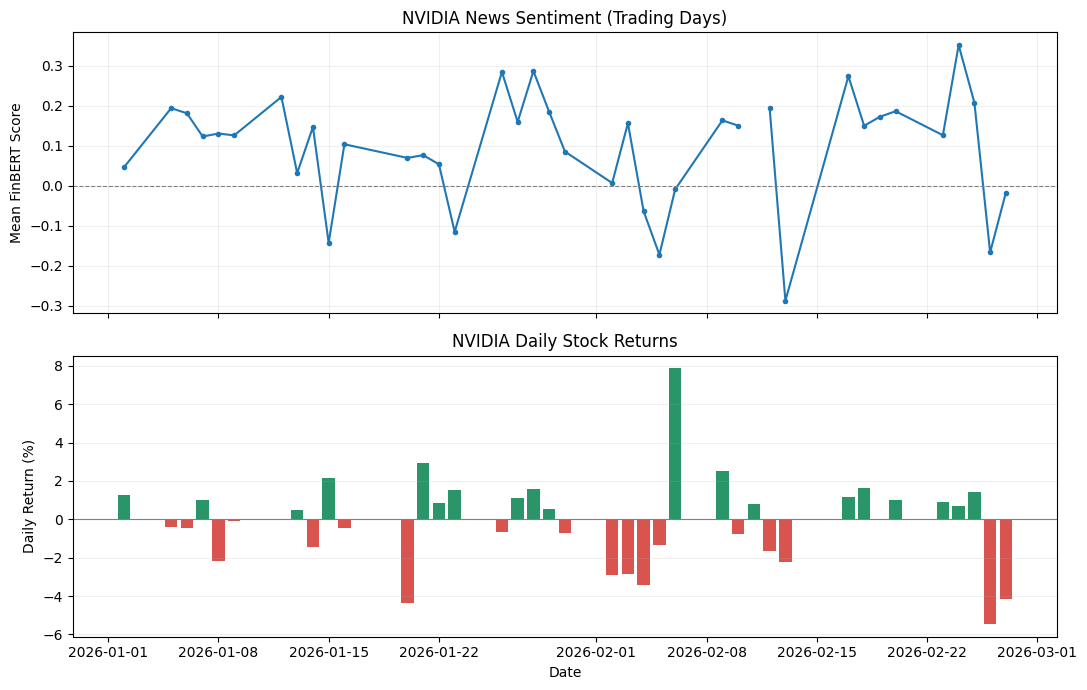

In [12]:
# Sentiment and stock returns over time

plot_data = market_sentiment.copy()
plot_data["Date"] = pd.to_datetime(plot_data["Date"])

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

# Daily news sentiment
axes[0].plot(
    plot_data["Date"],
    plot_data["mean_sentiment"],
    marker="o",
    markersize=3,
    linewidth=1.5
)
axes[0].axhline(0, color="gray", linestyle="--", linewidth=0.8)
axes[0].set_title("NVIDIA News Sentiment (Trading Days)")
axes[0].set_ylabel("Mean FinBERT Score")
axes[0].grid(alpha=0.2)

# Define conditional colors for returns
colors = ["#299568" if r >= 0 else "#D9534F" for r in plot_data["daily_return"]]

# Daily stock returns
axes[1].bar(
    plot_data["Date"],
    plot_data["daily_return"] * 100,
    width=0.8,
    color=colors
)
axes[1].axhline(0, color="gray", linewidth=0.8)
axes[1].set_title("NVIDIA Daily Stock Returns")
axes[1].set_ylabel("Daily Return (%)")
axes[1].set_xlabel("Date")
axes[1].grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


### Sentiment vs. Stock Returns

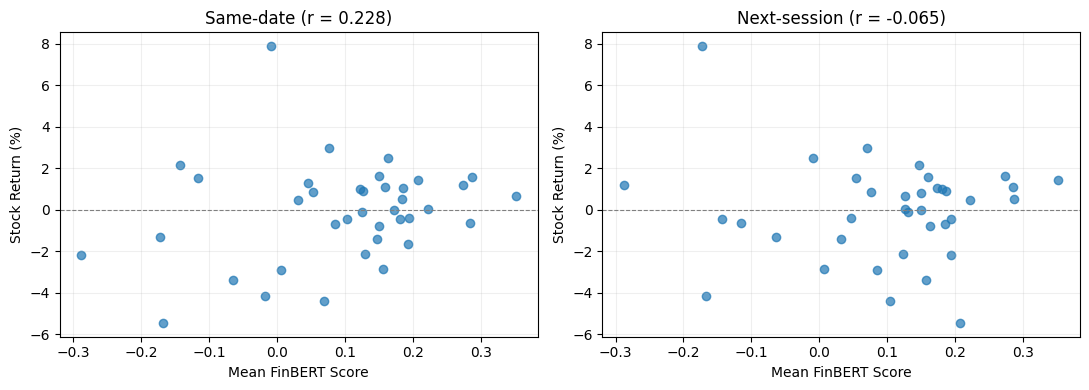

In [13]:
# Sentiment and stock-return correlations

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

comparisons = [
    ("Same-date", "daily_return"),
    ("Next-session", "next_session_return")
]

for ax, (name, return_col) in zip(axes, comparisons):
    paired = market_sentiment[
        ["mean_sentiment", return_col]
    ].dropna()

    r = pearsonr(
        paired["mean_sentiment"], paired[return_col]
    ).statistic

    ax.scatter(
        paired["mean_sentiment"],
        paired[return_col] * 100,
        alpha=0.7
    )

    ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
    ax.set_title(f"{name} (r = {r:.3f})")
    ax.set_xlabel("Mean FinBERT Score")
    ax.set_ylabel("Stock Return (%)")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


## 7. Robustness Checks

In [14]:
# Leave-one-out sensitivity analysis

sensitivity_results = []

for name, return_col in [
    ("Same-date", "daily_return"),
    ("Next-session", "next_session_return")
]:
    paired = market_sentiment[
        ["Date", "mean_sentiment", return_col]
    ].dropna().reset_index(drop=True)

    original_r = pearsonr(
        paired["mean_sentiment"], paired[return_col]
    ).statistic

    for i in range(len(paired)):
        subset = paired.drop(index=i)

        new_r = pearsonr(
            subset["mean_sentiment"], subset[return_col]
        ).statistic

        sensitivity_results.append({
            "Comparison": name,
            "Excluded date": paired.loc[i, "Date"],
            "Pearson r": new_r,
            "Change": new_r - original_r
        })

sensitivity = pd.DataFrame(sensitivity_results)

for name in ["Same-date", "Next-session"]:
    subset = sensitivity[sensitivity["Comparison"] == name].copy()
    subset["Absolute change"] = subset["Change"].abs()

    print(f"\n{name}")
    print("Minimum r:", round(subset["Pearson r"].min(), 4))
    print("Maximum r:", round(subset["Pearson r"].max(), 4))

    display(
        subset.sort_values("Absolute change", ascending=False)
        .head(5).round(4)
    )



Same-date
Minimum r: 0.127
Maximum r: 0.3622


,Comparison,Excluded date,Pearson r,Change,Absolute change
24,Same-date,2026-02-06,0.3622,0.1339,0.1339
36,Same-date,2026-02-26,0.1270,-0.1012,0.1012
9,Same-date,2026-01-15,0.2885,0.0603,0.0603
28,Same-date,2026-02-13,0.1841,-0.0442,0.0442
14,Same-date,2026-01-23,0.2677,0.0395,0.0395



Next-session
Minimum r: -0.1719
Maximum r: 0.151


,Comparison,Excluded date,Pearson r,Change,Absolute change
61,Next-session,2026-02-05,0.1510,0.2157,0.2157
74,Next-session,2026-02-26,-0.1719,-0.1072,0.1072
73,Next-session,2026-02-25,-0.0173,0.0474,0.0474
66,Next-session,2026-02-13,-0.0260,0.0387,0.0387
72,Next-session,2026-02-24,-0.1020,-0.0373,0.0373


In [15]:
# Compare NVIDIA-specific and full news samples

sample_comparison = stock[["Date", "daily_return"]].copy()
sample_comparison["next_session_return"] = (
    sample_comparison["daily_return"].shift(-1)
)

sample_comparison = sample_comparison.merge(
    daily_primary[["Date", "mean_sentiment"]].rename(
        columns={"mean_sentiment": "sentiment_primary"}
    ),
    on="Date",
    how="left",
    validate="one_to_one"
)

sample_comparison = sample_comparison.merge(
    daily_full[["Date", "mean_sentiment"]].rename(
        columns={"mean_sentiment": "sentiment_full"}
    ),
    on="Date",
    how="left",
    validate="one_to_one"
)

results = []

for name, return_col in [
    ("Same-date", "daily_return"),
    ("Next-session", "next_session_return")
]:
    paired = sample_comparison[
        ["sentiment_primary", "sentiment_full", return_col]
    ].dropna()

    for sample, sentiment_col in [
        ("Primary", "sentiment_primary"),
        ("Full", "sentiment_full")
    ]:
        test = pearsonr(paired[sentiment_col], paired[return_col])

        results.append({
            "Comparison": name,
            "Sample": sample,
            "Observations": len(paired),
            "Pearson r": test.statistic,
            "P-value": test.pvalue
        })

sample_robustness = pd.DataFrame(results)

display(sample_robustness.round(4))


,Comparison,Sample,Observations,Pearson r,P-value
0,Same-date,Primary,38,0.2283,0.1681
1,Same-date,Full,38,0.2303,0.1642
2,Next-session,Primary,37,-0.0647,0.7035
3,Next-session,Full,37,-0.0650,0.7022


In [16]:
# Assign weekend and holiday news to the next trading session

calendar = pd.DataFrame({
    "session_date": pd.to_datetime(stock["Date"])
})

news_mapped = news_primary[["Date", "sentiment_score"]].copy()
news_mapped["publication_date"] = pd.to_datetime(news_mapped["Date"])

news_mapped = pd.merge_asof(
    news_mapped.sort_values("publication_date"),
    calendar.sort_values("session_date"),
    left_on="publication_date",
    right_on="session_date",
    direction="forward"
)

reassigned = (
    news_mapped["session_date"].notna() &
    (news_mapped["publication_date"] != news_mapped["session_date"])
).sum()

print("Headlines reassigned:", reassigned)
print("Headlines unassigned:", news_mapped["session_date"].isna().sum())

# Aggregate sentiment by assigned trading session

daily_mapped = (
    news_mapped.dropna(subset=["session_date"])
    .groupby("session_date", as_index=False)
    .agg(sentiment_mapped=("sentiment_score", "mean"))
)

# Compare with original publication-date alignment

alignment = market_sentiment[
    ["Date", "mean_sentiment", "daily_return", "next_session_return"]
].copy()

alignment["Date"] = pd.to_datetime(alignment["Date"])

alignment = alignment.merge(
    daily_mapped,
    left_on="Date",
    right_on="session_date",
    how="left",
    validate="one_to_one"
)

results = []

for name, return_col in [
    ("Same-date", "daily_return"),
    ("Next-session", "next_session_return")
]:
    paired = alignment[
        ["mean_sentiment", "sentiment_mapped", return_col]
    ].dropna()

    for method, sentiment_col in [
        ("Original", "mean_sentiment"),
        ("Calendar-aligned", "sentiment_mapped")
    ]:
        test = pearsonr(paired[sentiment_col], paired[return_col])

        results.append({
            "Comparison": name,
            "Method": method,
            "Observations": len(paired),
            "Pearson r": test.statistic,
            "P-value": test.pvalue
        })

alignment_results = pd.DataFrame(results)

display(alignment_results.round(4))


Headlines reassigned: 169
Headlines unassigned: 8


,Comparison,Method,Observations,Pearson r,P-value
0,Same-date,Original,38,0.2283,0.1681
1,Same-date,Calendar-aligned,38,0.2330,0.1592
2,Next-session,Original,37,-0.0647,0.7035
3,Next-session,Calendar-aligned,37,-0.0864,0.6111



## 8. Findings and Limitations

### Key Findings

FinBERT was used to analyze 1,526 financial-news headlines collected between January and February 2026. Of these, 1,498 explicitly mentioned NVIDIA or NVDA and were retained for the primary analysis.

**Sentiment and stock returns:**

- Same-date sentiment showed a weak positive correlation with NVIDIA returns (r = 0.2283, p = 0.1681; n = 38).
- Next-session sentiment showed little linear relationship with returns (r = -0.0647, p = 0.7035; n = 37).
- Neither relationship was statistically significant at the 5% level.

**Robustness:**

- Including all retrieved headlines produced nearly identical correlations.
- Assigning weekend and holiday news to the next trading session had little effect on the overall results.
- Leave-one-out analysis showed that individual trading days influenced the correlations, particularly the next-session relationship.

### Limitations

- **News coverage:** Google News retrieval was inconsistent across date ranges, and the collected headlines do not represent an exhaustive news archive.
- **Publication timing:** Most retrieved timestamps appeared standardized, preventing reliable separation of premarket, intraday, and after-hours news.
- **Sentiment interpretation:** FinBERT evaluates financial sentiment in the headline, which may not reflect whether the news is positive or negative specifically for NVIDIA.
- **Sample size:** The analysis covers only 39 trading sessions, limiting statistical precision.
- **Market factors:** Stock returns are affected by earnings, macroeconomic conditions, investor expectations, and other factors not captured by headline sentiment.